## EDA

In [50]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [51]:
df=pd.read_csv("credit_risk_dataset.csv")

In [52]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [53]:
df.shape

(32581, 12)

In [54]:
df.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='str')

In [55]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.5 MB


In [56]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [57]:
df['loan_status'].unique() #  It is Binary class problem  

array([1, 0])

In [58]:
# checking class imbalace
df['loan_status'].value_counts()

loan_status
0    25473
1     7108
Name: count, dtype: int64

<Axes: xlabel='loan_status', ylabel='count'>

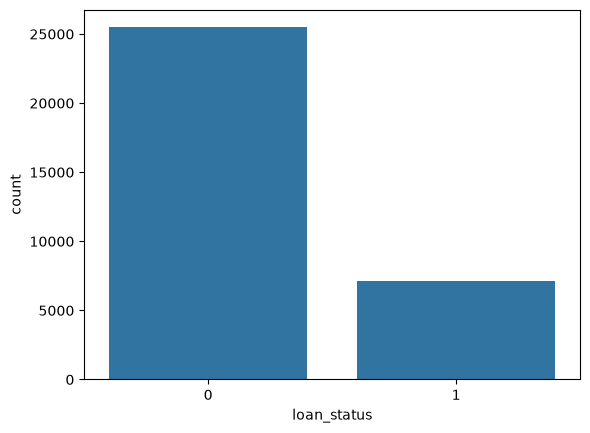

In [59]:
sns.countplot(x='loan_status',data=df)

In [60]:
# outlier check
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


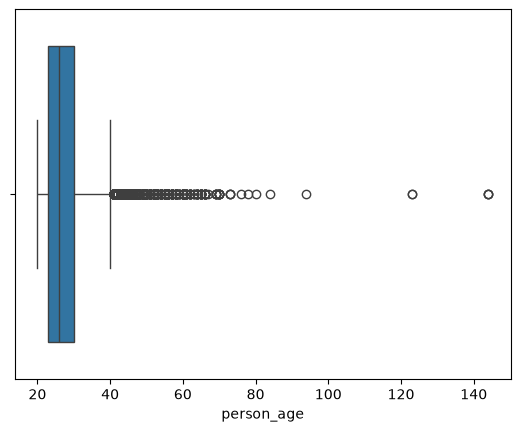

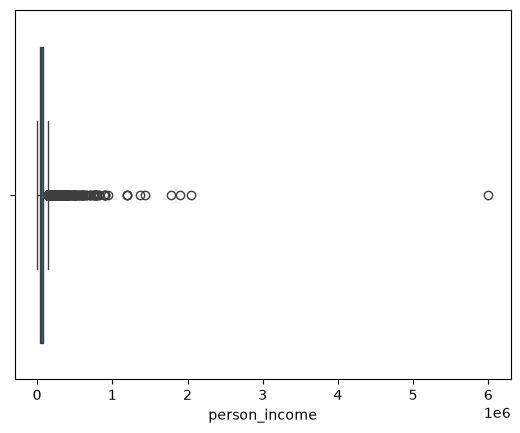

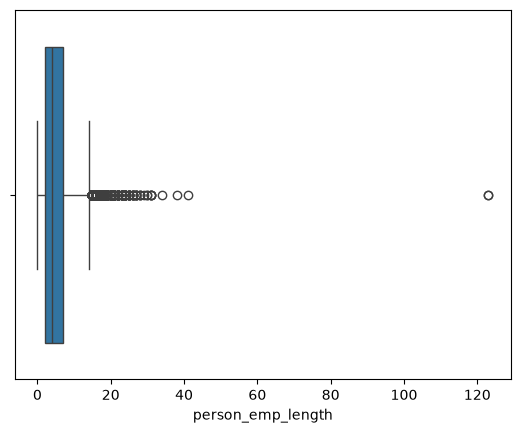

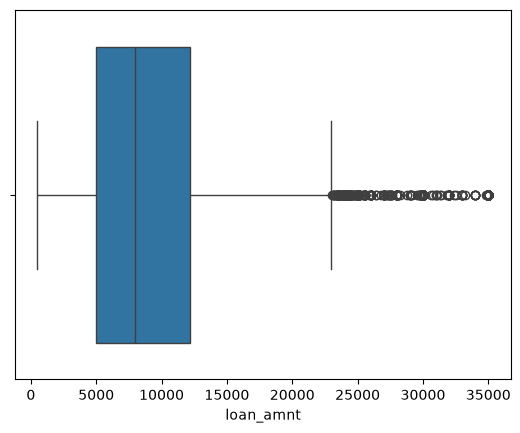

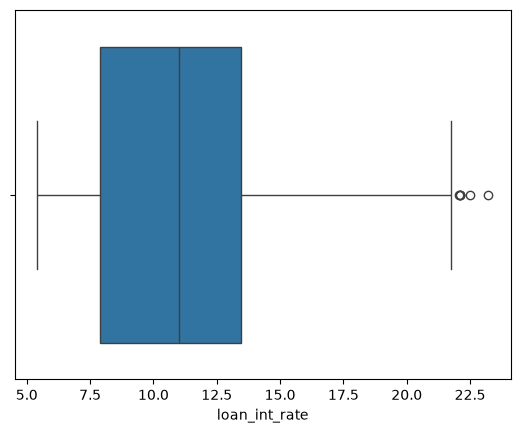

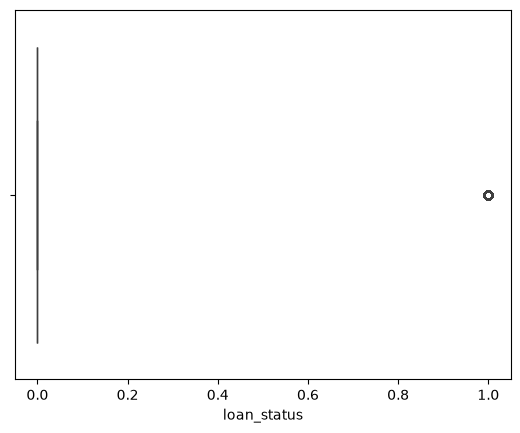

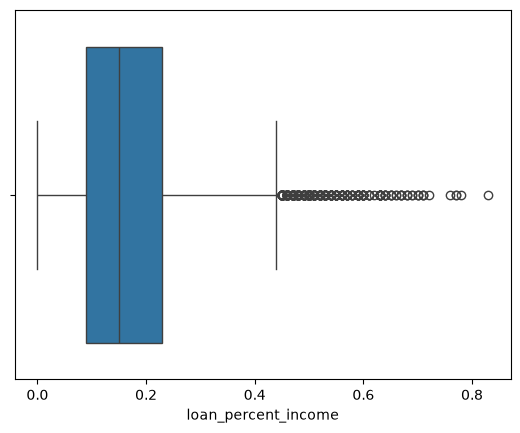

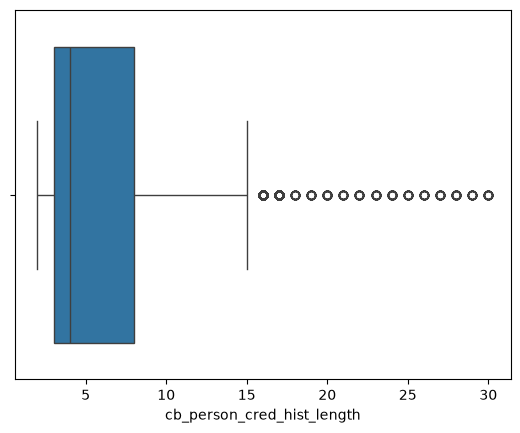

In [61]:
# plotting box plots , applicable only for numeical cols
numerical_cols=df.select_dtypes(include=np.number)
for i in numerical_cols:
    sns.boxplot(x=df[i])
    plt.show()

In [62]:
(df['person_age']>100).sum()

np.int64(5)

In [63]:
(df['person_emp_length']>60).sum()

np.int64(2)

<Axes: >

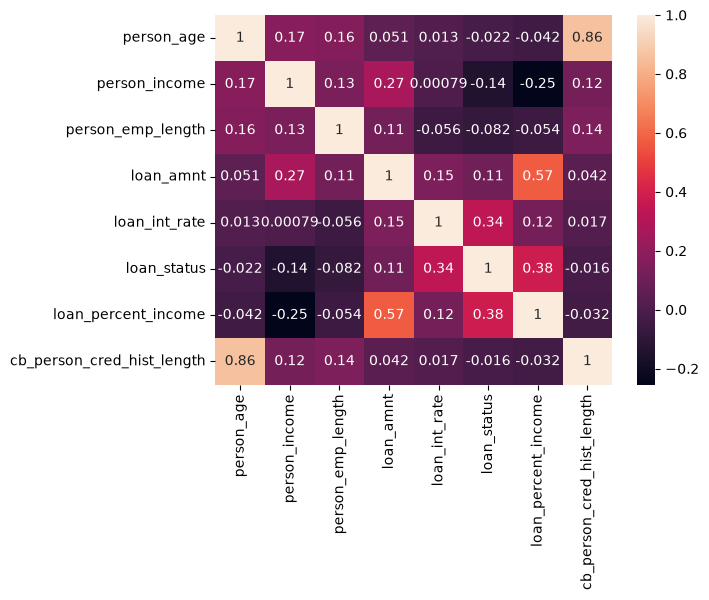

In [64]:
# correlation map
sns.heatmap(df.corr(numeric_only=True),annot=True)

## 3. Data Validation & Outlier Handling
- Here we clean the data properly.
- We remove duplicate rows.
- We remove rows with an impossible age or work experience.
- We remove rows with zero or negative income and loan amount.
- We check if the interest rate looks realistic.
- We also flag rows where numbers don't add up correctly.

In [65]:
df_copy = df.copy()
print(f"Original Rows: {df_copy.shape[0]}")

# Remove duplicate rows
df_copy = df_copy.drop_duplicates()
print(f"After duplicates: {df_copy.shape[0]}")

# Age must be between 18 and 100
df_copy = df_copy[df_copy['person_age'].between(18, 100)]

# FIX 5: keep rows where emp_length is missing (NaN). The imputer will fill them.
# Only remove rows where emp_length is a real bad value.
valid_emp = (
    df_copy['person_emp_length'].isna() |
    ((df_copy['person_emp_length'] <= df_copy['person_age']) &
     (df_copy['person_emp_length'] <= 60))
)
df_copy = df_copy[valid_emp]

# FIX 6: now the code really matches the comment (income AND loan amount > 0)
df_copy = df_copy[df_copy['person_income'] > 0]
df_copy = df_copy[df_copy['loan_amnt'] > 0]

# FIX 6: handle the extreme income outliers (9 rows are above 1,000,000)
df_copy = df_copy[df_copy['person_income'] <= 1_000_000]

# Interest rate: keep NaN, remove only unrealistic values
df_copy = df_copy[df_copy['loan_int_rate'].isna() | df_copy['loan_int_rate'].between(0, 40)]

# FIX 8 (training side): calculate it ourselves so training and API use the same formula
df_copy['loan_percent_income'] = df_copy['loan_amnt'] / df_copy['person_income']

print(f"Final rows: {df_copy.shape[0]}")
print("Missing emp_length kept:", df_copy['person_emp_length'].isna().sum())

Original Rows: 32581
After duplicates: 32416
Final rows: 32401
Missing emp_length kept: 887


In [66]:
df_copy.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32401.000000,32401.000000,31514.000000,32401.000000,29309.000000,32401.000000,32401.000000,32401.000000
mean,27.726366,65536.367427,4.782414,9592.788031,11.017452,0.218759,0.170637,5.808524
std,6.202852,47058.333650,4.036804,6321.426226,3.241690,0.413411,0.107036,4.053660
min,20.000000,4000.000000,0.000000,500.000000,5.420000,0.000000,0.001282,2.000000
25%,23.000000,38500.000000,2.000000,5000.000000,7.900000,0.000000,0.089744,3.000000
50%,26.000000,55000.000000,4.000000,8000.000000,10.990000,0.000000,0.148148,4.000000
75%,30.000000,79200.000000,7.000000,12250.000000,13.470000,0.000000,0.229167,8.000000
max,94.000000,948000.000000,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


## 4. Features, Target & Train-Test Split
- We separate the data into input features and the target.
- The target is whether the applicant defaulted or not.
- We split the data into a training part and a testing part.
- The model learns from the training part only.


In [67]:
X=df_copy.drop('loan_status',axis=1)
y=df_copy['loan_status']

In [68]:
from sklearn.model_selection import train_test_split
X_train , X_test , y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [69]:
numerical_cols=['person_age', 'person_income', 
       'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income',
       'cb_person_cred_hist_length']
categorical_cols=['person_home_ownership',
       'loan_intent', 'loan_grade', 
       'cb_person_default_on_file']

In [70]:
# Handle Class Imbalance Using class weights
#0 -> no loan (most)
#1 -> yes loan

neg, pos = np.bincount(y_train)
scale_weigths = neg/pos


##  Data Preprocessing — Pipelines & Column Transformer
- Raw data is not ready for a model directly.
- We need to prepare numeric and text columns differently.
- We will build a Pipeline for each model.
- We will use ColumnTransformer to apply different steps to different columns.

## Preprocessing for Logistic Regression
- Fill missing numeric values.
- Scale numeric values, since this model is sensitive to scale.
- Convert category columns into numbers using one-hot encoding.

In [71]:
# Logistic Regression : impute + scale numeric , impute + oneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler , OneHotEncoder

preprocessor_lr=ColumnTransformer(
    transformers=[
        ('num',Pipeline(
            [('imputer', SimpleImputer(strategy='median')),
             ('scaler',StandardScaler())
             ]),numerical_cols),

        ('cat',Pipeline([
            ('imputer',SimpleImputer(strategy='constant',fill_value="Missing")),
        ('oneHot',OneHotEncoder(handle_unknown='ignore'))
        ]),categorical_cols)
    ]
)

In [72]:
# xgBoost : Impute numeric only no scaling, impute+oneHotEncoder
# It automatically does Scaling , don't need to do explicitly
preprocessor_xg=ColumnTransformer(
    transformers=[
        ('num',Pipeline(
            [('imputer', SimpleImputer(strategy='median'))
             ]),numerical_cols),

        ('cat',Pipeline([
            ('imputer',SimpleImputer(strategy='constant',fill_value="Missing")),
        ('oneHot',OneHotEncoder(handle_unknown='ignore'))
        ]),categorical_cols)
    ]
)

#### Evaluation

In [73]:
def evaluate_model(model_name, model, X_test, y_test, threshold=None):
    y_pred_prob = model.predict_proba(X_test)[:, 1]

    if threshold is not None:
        y_pred = (y_pred_prob >= threshold).astype(int)   # same rule as the API
    else:
        y_pred = model.predict(X_test)

    print(f"{model_name} Metrics:")
    if threshold is not None:
        print(f"Used Threshold : {threshold:.3f}")
    print(f"Accuracy  : {accuracy_score(y_test, y_pred):.2f}")
    print(f"Precision : {precision_score(y_test, y_pred):.2f}")
    print(f"Recall    : {recall_score(y_test, y_pred):.2f}")
    print(f"F1        : {f1_score(y_test, y_pred):.2f}")
    print()
    print(classification_report(y_test, y_pred))

    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d")
    plt.title(f"{model_name} Confusion Matrix")
    plt.ylabel("Actual Values")
    plt.xlabel("Predicted Values")
    plt.show()

    # renamed variables so we do not overwrite `threshold`
    prec_curve, rec_curve, _ = precision_recall_curve(y_test, y_pred_prob)
    plt.plot(rec_curve, prec_curve)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"{model_name} Precision-Recall Curve")
    plt.show()

In [74]:
# stratified cross validation
from sklearn.model_selection import StratifiedKFold ,cross_validate
from sklearn.model_selection import cross_validate
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
scoring={
    'roc_auc':"roc_auc",
    'accuracy':"accuracy",
    "precision":"precision",
    'recall':'recall',
    'f1':'f1'
}

In [75]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline=Pipeline([
    ('preprocessor',preprocessor_lr),
    ('classifier',LogisticRegression(max_iter=1000,class_weight="balanced",random_state=42))
])
lr_cv_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3I

In [76]:
# xgBoost model 
import pip
!pip install xgboost
from xgboost import XGBClassifier
xg_cv_pipeline=Pipeline([
    ('preprocessor',preprocessor_xg),
    ('classifier',XGBClassifier(
        n_estimators=300,max_depth=5,learning_rate=0.1,scale_pos_weight=scale_weigths,random_state=42
    ))
])

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [77]:
 # model or pipeline
# train test 
# cross validation
# scoring

In [78]:
for cv_name, pipe in [("Logistic Regression", lr_cv_pipeline),
                      ("XGBoost", xg_cv_pipeline)]:

                      cv_results = cross_validate(pipe, X_train , y_train, cv=cv, scoring=scoring, n_jobs=-1)
                      

                      print(cv_name)
                      print(f"ROC-AUC : {cv_results['test_roc_auc'].mean()}")
                      print(f"Accuracy : {cv_results['test_accuracy'].mean()}")
                      print(f"Precision : {cv_results['test_precision'].mean()}")
                      print(f"Recall : {cv_results['test_recall'].mean()}")
                      print(f"F1 : {cv_results['test_f1'].mean()}")
                      print()

Logistic Regression
ROC-AUC : 0.8713477475123567
Accuracy : 0.8118827160493828
Precision : 0.5498580891486224
Recall : 0.7746031746031747
F1 : 0.6430980953914689

XGBoost
ROC-AUC : 0.9457726827356459
Accuracy : 0.9150077160493826
Precision : 0.8125335928648003
Recall : 0.7948853615520282
F1 : 0.8035533252234941



In [79]:
 # Baseline Model Logistic Regression
from sklearn.pipeline import Pipeline
baseline_model=Pipeline([
    ('Preprocessor',preprocessor_lr),
    ('Classifier',LogisticRegression(class_weight="balanced"))
])
baseline_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocessor', ...), ('Classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped

In [80]:
xg_model=Pipeline([
    ('preprocessor',preprocessor_xg),
    ('classifer',XGBClassifier(learning_rate=0.1,scale_pos_weight=scale_weigths,random_state=42
))
])
xg_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifer', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped.

baseline Logistic Model Metrics:
Accuracy  : 0.82
Precision : 0.56
Recall    : 0.78
F1        : 0.65

              precision    recall  f1-score   support

           0       0.93      0.83      0.88      5063
           1       0.56      0.78      0.65      1418

    accuracy                           0.82      6481
   macro avg       0.75      0.81      0.77      6481
weighted avg       0.85      0.82      0.83      6481



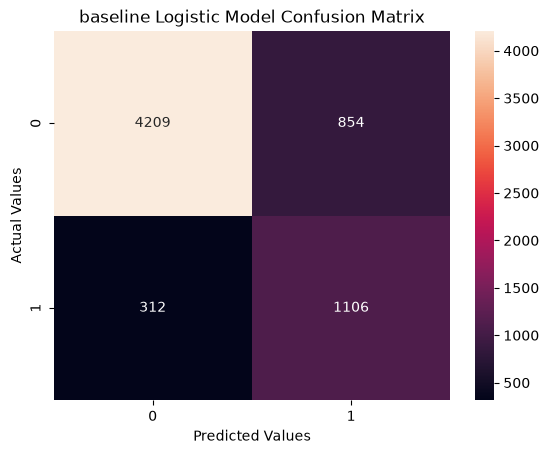

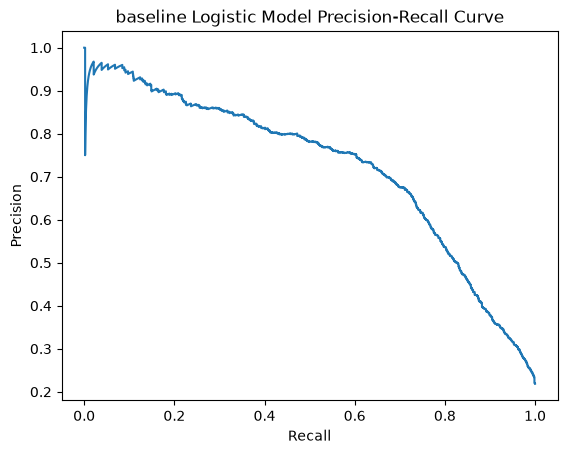

In [81]:
# Evaluation
evaluate_model("baseline Logistic Model",baseline_model,X_test,y_test)

baseline XgBoost Model Metrics:
Accuracy  : 0.92
Precision : 0.83
Recall    : 0.80
F1        : 0.82

              precision    recall  f1-score   support

           0       0.94      0.95      0.95      5063
           1       0.83      0.80      0.82      1418

    accuracy                           0.92      6481
   macro avg       0.89      0.88      0.88      6481
weighted avg       0.92      0.92      0.92      6481



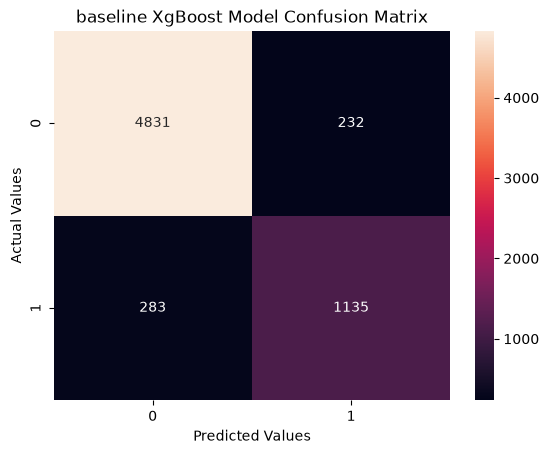

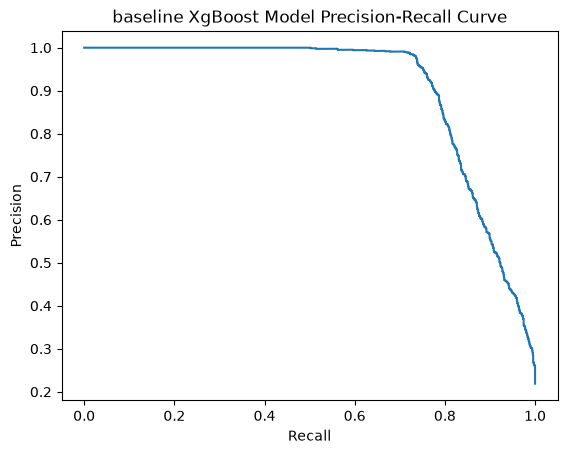

In [82]:
evaluate_model("baseline XgBoost Model",xg_model,X_test,y_test)

In [83]:
from scipy.stats import uniform,randint
from sklearn.model_selection import RandomizedSearchCV
param_grid={
    "classifer__n_estimators":randint(150,600),
    "classifer__max_depth":randint(3,9),
    "classifer__learning_rate":uniform(0.01,0.5),
    "classifer__subsample":uniform(0.6,0.4),
    "classifer__colsample_bytree":uniform(0.6,0.4),
    "classifer__min_child_weight":randint(1,10),
    "classifer__gamma":uniform(0,5)


}

In [84]:
random_search=RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1
)
random_search.fit(X_train,y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifer__colsample_bytree': <scipy.stats....00269E260EBE0>, 'classifer__gamma': <scipy.stats....00269E260E250>, 'classifer__learning_rate': <scipy.stats....00269E271DF30>, 'classifer__max_depth': <scipy.stats....00269E271EB10>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",150
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` 

In [85]:
random_search.best_params_

{'classifer__colsample_bytree': np.float64(0.8516427729593735),
 'classifer__gamma': np.float64(0.16409995834350322),
 'classifer__learning_rate': np.float64(0.07364621235111966),
 'classifer__max_depth': 8,
 'classifer__min_child_weight': 7,
 'classifer__n_estimators': 285,
 'classifer__subsample': np.float64(0.7939429111777896)}

In [86]:
print("score after performing tuning",random_search.best_score_)

score after performing tuning 0.9015191713611779


logistic Reggression Metrics:
Accuracy  : 0.82
Precision : 0.56
Recall    : 0.78
F1        : 0.65

              precision    recall  f1-score   support

           0       0.93      0.83      0.88      5063
           1       0.56      0.78      0.65      1418

    accuracy                           0.82      6481
   macro avg       0.75      0.81      0.77      6481
weighted avg       0.85      0.82      0.83      6481



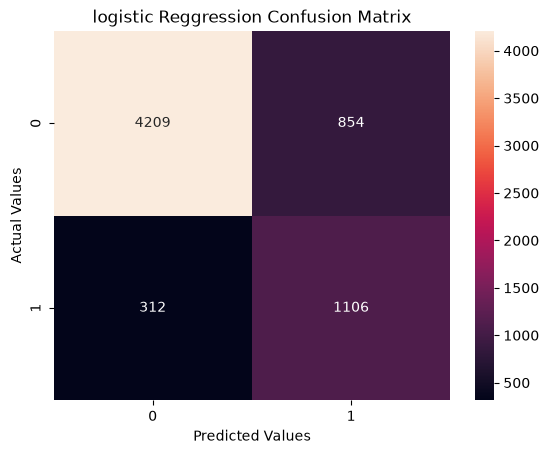

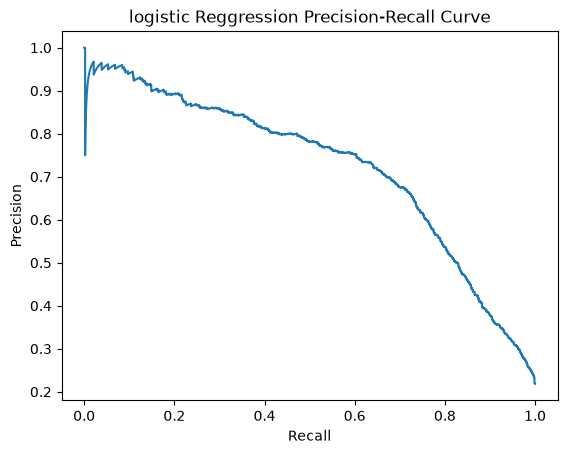

In [87]:
# compare both model
evaluate_model("logistic Reggression",baseline_model,X_test,y_test)

xgBoost after tuning Metrics:
Accuracy  : 0.93
Precision : 0.87
Recall    : 0.80
F1        : 0.83

              precision    recall  f1-score   support

           0       0.95      0.96      0.96      5063
           1       0.87      0.80      0.83      1418

    accuracy                           0.93      6481
   macro avg       0.91      0.88      0.89      6481
weighted avg       0.93      0.93      0.93      6481



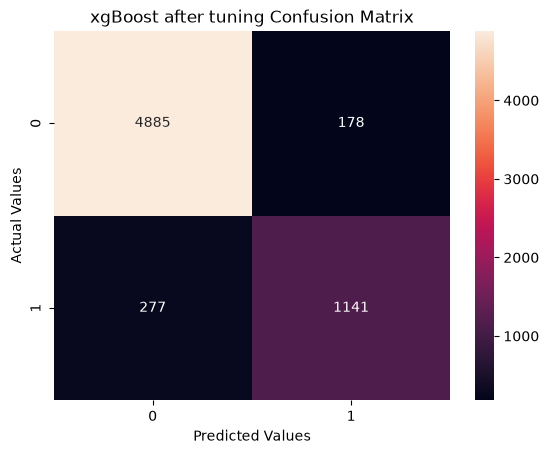

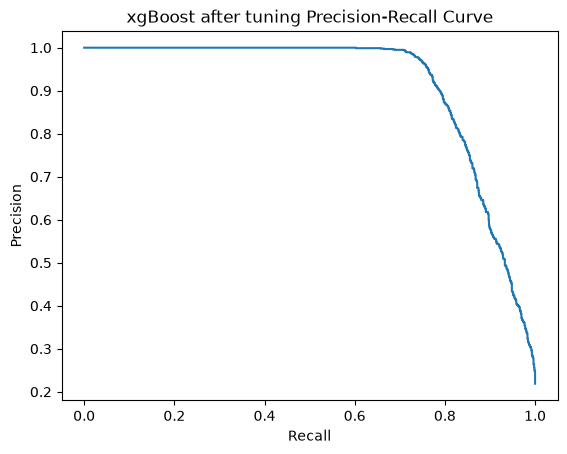

In [88]:
evaluate_model("xgBoost after tuning",random_search,X_test,y_test)

## 12. Optimizing the Classification Threshold
- The model gives a probability, not a direct yes or no.
- We decide a cut-off point to turn it into a decision.
- We check different cut-off points and pick the best one.

## 13. Probability Calibration
- Sometimes a model's probability doesn't mean what it says.
- For example, 30% risk should truly mean a 30% chance.
- We check this with a calibration plot.
- We fix it if the probabilities are off.

In [ ]:
"""
Methods by which we can fix the poorly calibrated model.
1. Platt Scaling/ Sigmoid -> Adjust the probabilites using a sigmoid curve.
2. Isotonic Regression -> Learn a flexible mapping from old prob. - better prob. (non-linear calibartion)
3. Temperature Scaling -> Adjust the confidence of neural-network predictions using one temperature
"""

'\nMethods by which we can fix the poorly calibrated model.\n1. Platt Scaling/ Sigmoid -> Adjust the probabilites using a sigmoid curve.\n2. Isotonic Regression -> Learn a flexible mapping from old prob. - better prob. (non-linear calibartion)\n3. Temperature Scaling -> Adjust the confidence of neural-network predictions using one temperature\n'

In [90]:
#1. Calibrated XGBoost model
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(
    best_model,
    method="sigmoid",
    cv=5
)

calibrated_model.fit(X_train, y_train)

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2","Pipeline(step...=None, ...))])"
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'sigmoid'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",'auto'
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated classifier case when `ensemble=False`.",list,"[<sklearn.cali...0026A28BA0590>, <

In [91]:
#2. Get probabilites
uncalibrated = best_model.predict_proba(X_test)[:,1]
calibrated = calibrated_model.predict_proba(X_test)[:,1]

In [92]:
#3. create calibration curves
actual_uncal, predicted_uncal = calibration_curve(y_test, uncalibrated, n_bins=10)

In [93]:
actual_cal, predicted_cal  = calibration_curve(y_test, calibrated, n_bins=10)

Best threshold: 0.558 | OOF F1: 0.828
Calibrated XGBoost Metrics:
Used Threshold : 0.558
Accuracy  : 0.94
Precision : 0.95
Recall    : 0.77
F1        : 0.85

              precision    recall  f1-score   support

           0       0.94      0.99      0.96      5063
           1       0.95      0.77      0.85      1418

    accuracy                           0.94      6481
   macro avg       0.94      0.88      0.91      6481
weighted avg       0.94      0.94      0.94      6481



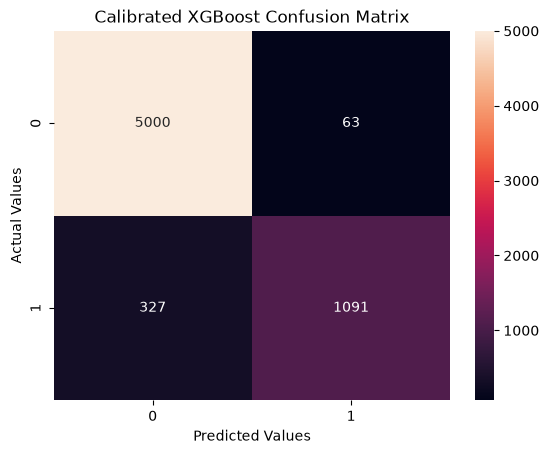

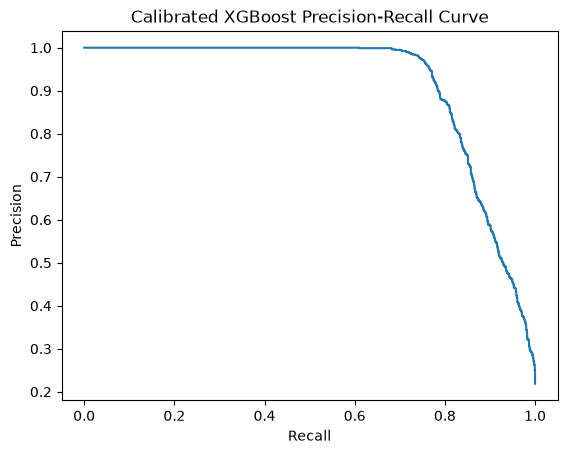

In [94]:
from sklearn.model_selection import cross_val_predict

# 1. Out-of-fold probabilities from the FINAL (calibrated, tuned) model, TRAIN data only
oof_prob = cross_val_predict(
    calibrated_model, X_train, y_train, cv=cv, method="predict_proba"
)[:, 1]

# 2. Precision / recall for each threshold
precisions, recalls, thresholds = precision_recall_curve(y_train, oof_prob)

# 3. FIX 1: correct F1 formula (multiply, not subtract)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-12)

# 4. Best threshold
best_idx = np.argmax(f1_scores[:-1])
best_threshold = float(thresholds[best_idx])   # plain float, easy to save and load
print(f"Best threshold: {best_threshold:.3f} | OOF F1: {f1_scores[best_idx]:.3f}")

# 5. Test set is used ONCE, only to report the final result
evaluate_model("Calibrated XGBoost", calibrated_model, X_test, y_test, best_threshold)

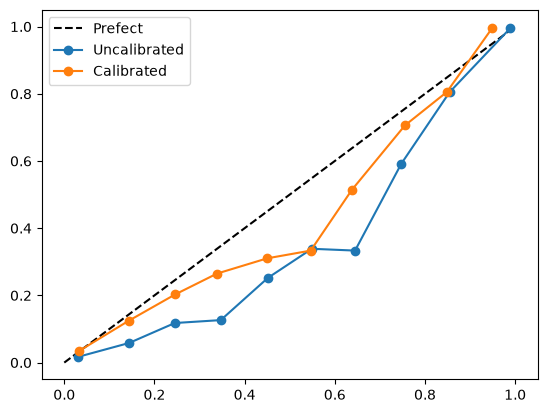

In [95]:
#4. plot
plt.plot([0,1], [0,1], 'k--', label="Prefect")
plt.plot(
    predicted_uncal,
    actual_uncal,
    "o-",
    label = "Uncalibrated"
)

plt.plot(
    predicted_cal,
    actual_cal,
    "o-",
    label = "Calibrated"
)
plt.legend()

## 14. SHAP Interpretation — Global & Local
- SHAP helps us understand why the model makes a decision.
- It is a way of explaining a "black box" model.

In [96]:
!pip install shap

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [97]:
import shap

C:\Users\vagis\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [99]:
# 2. Use the FINAL tuned model, not xg_model
final_pipe = random_search.best_estimator_
xgb_classifier = final_pipe.named_steps['classifer']

# 3.
X_test_transformed = final_pipe.named_steps['preprocessor'].transform(X_test)

# 4.
feature_names = final_pipe.named_steps['preprocessor'].get_feature_names_out()

In [100]:
#5. Convert to a dataframe for cleaner SHAP plots
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)
X_test_df

,num__person_age,num__person_income,num__person_emp_length,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__cb_person_cred_hist_length,cat__person_home_ownership_MORTGAGE,cat__person_home_ownership_OTHER,cat__person_home_ownership_OWN,...,cat__loan_intent_VENTURE,cat__loan_grade_A,cat__loan_grade_B,cat__loan_grade_C,cat__loan_grade_D,cat__loan_grade_E,cat__loan_grade_F,cat__loan_grade_G,cat__cb_person_default_on_file_N,cat__cb_person_default_on_file_Y
0,29.0,75000.0,4.0,5000.0,15.62,0.066667,10.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,21.0,45000.0,5.0,4000.0,12.87,0.088889,2.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,25.0,30000.0,9.0,3000.0,11.71,0.100000,3.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,27.0,48996.0,3.0,12000.0,12.53,0.244918,8.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,44.0,60000.0,4.0,15000.0,10.99,0.250000,11.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6476,40.0,70000.0,6.0,18000.0,7.90,0.257143,14.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6477,31.0,59000.0,14.0,20000.0,7.51,0.338983,10.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6478,28.0,55000.0,12.0,7000.0,10.99,0.127273,6.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6479,23.0,60000.0,8.0,10000.0,10.99,0.166667,3.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [101]:
#6. Create SHAP explainer built for tree-based model
explainer = shap.TreeExplainer(xgb_classifier)
explainer

In [102]:
#7. Calculate SHAP values for every row in the test set
shap_values = explainer.shap_values(X_test_df)
shap_values


array([[-1.2635565e-01, -1.0797273e+00, -2.2765329e-01, ...,
        -1.8136567e-02,  6.5041808e-03, -3.9155330e-03],
       [-1.2452456e-01, -9.2352277e-01, -3.9019418e-01, ...,
        -7.8363735e-03,  2.3504907e-02, -2.1540295e-02],
       [ 1.6864052e-02,  9.1835934e-01,  8.1670627e-02, ...,
        -7.6798508e-03, -2.8647050e-02, -7.3115213e-04],
       ...,
       [-4.7738791e-02, -8.7572330e-01,  2.8371230e-01, ...,
        -7.7060461e-03, -8.1061283e-03, -2.0489593e-03],
       [ 2.3505752e-01, -1.0312788e+00,  2.0823126e-01, ...,
        -7.9740454e-03, -5.1252816e-02, -7.2287023e-03],
       [ 3.8914639e-01,  7.0770912e-02, -1.3091406e-01, ...,
        -5.8489679e-03, -7.4047721e-03, -9.0963242e-04]],
      shape=(6481, 26), dtype=float32)

### Global explanation
- This shows which features matter most overall.
- It also shows if a feature increases or decreases risk.

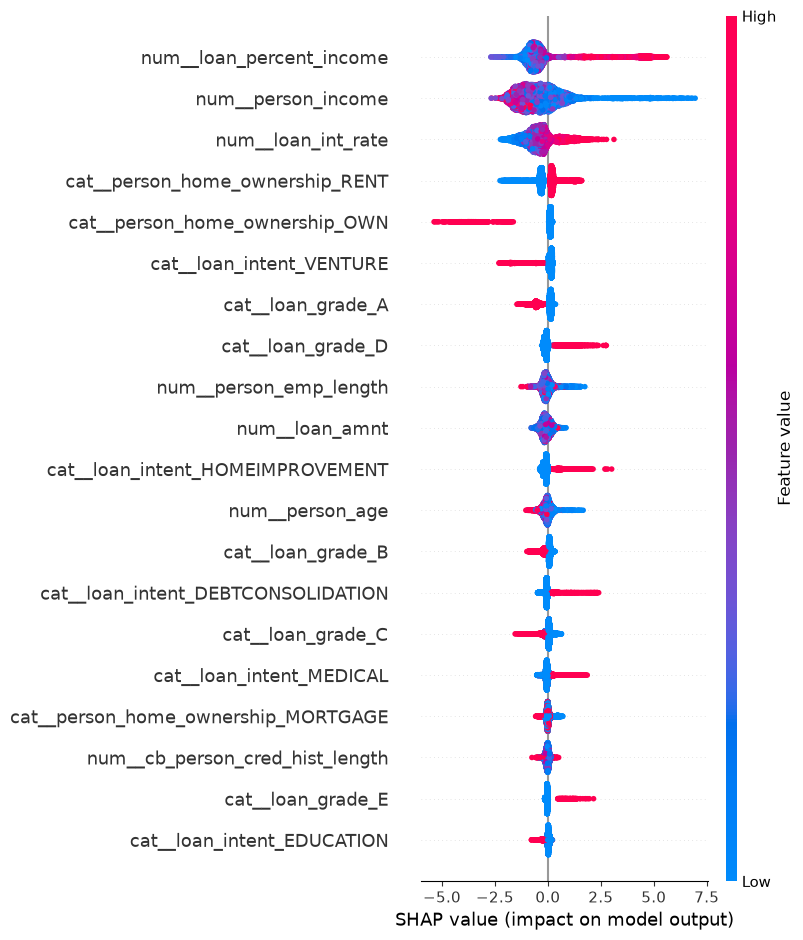

In [103]:
shap.summary_plot(shap_values,X_test_df)

### Local explanation
- This shows why one specific applicant got their score.
- It breaks the score down feature by feature.

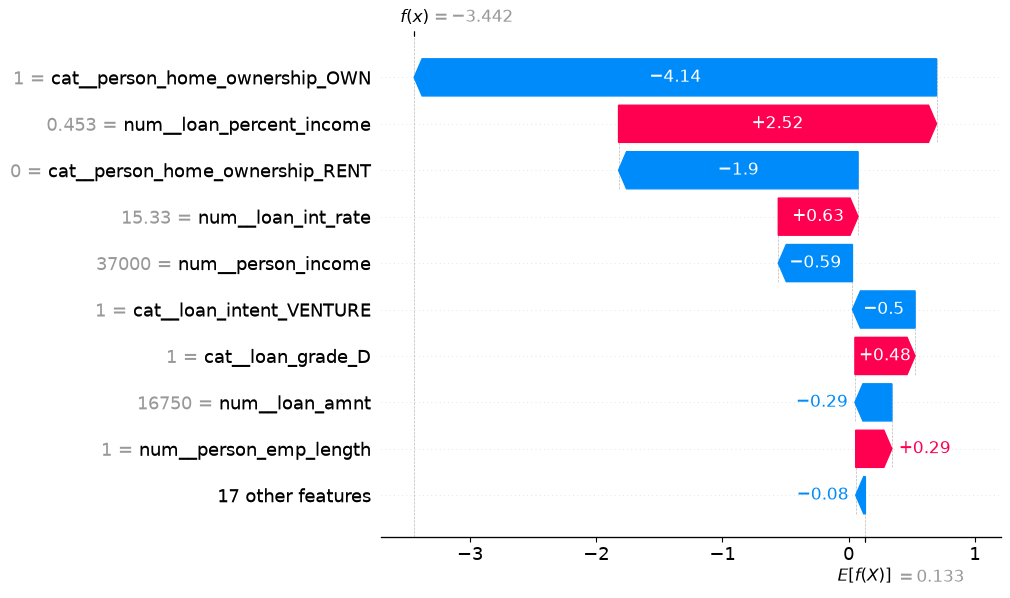

In [104]:
# 1. Pick one row to explain, e.g. the 5th applicant in the test set
row_index = 5

#2. Draw a waterfall plot showing how each feature pushed the prediction up or down.
shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,
        data = X_test_df.iloc[row_index],
        feature_names = feature_names
    )
)

## 15. Analyzing False Positives & False Negatives
- The model will not be perfect.
- False positives are safe people wrongly marked risky.
- False negatives are risky people wrongly marked safe.
- We study these cases to understand where the model struggles.
 

In [105]:
#Get predictions from the best performing XGBoost model on the test set
y_pred = random_search.predict(X_test)

In [106]:
#Create a dataframe to easily compare the actual and predicted values
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred

In [107]:
#Identify False Positive : Model Predicted 1, but the actual was 0
false_positive = result_df[(result_df['actual']== 0) & (result_df['predicted']== 1)]

#Identify False Negative : Model Predicted 0, but the actual was 1
false_negative = result_df[(result_df['actual']== 1) & (result_df['predicted']== 0)]

In [108]:
print(f"False Positive : {len(false_positive)}")
print(f"False Negative : {len(false_negative)}")

False Positive : 178
False Negative : 277


In [109]:
import sklearn, xgboost, pandas, joblib, sys
print("python      ", sys.version.split()[0])
print("scikit-learn", sklearn.__version__)
print("xgboost     ", xgboost.__version__)
print("pandas      ", pandas.__version__)
print("joblib      ", joblib.__version__)

python       3.14.5
scikit-learn 1.9.0
xgboost      3.4.0
pandas       3.0.5
joblib       1.5.3


In [110]:
import joblib

joblib.dump(calibrated_model, "credit_risk_model.pkl")

['credit_risk_model.pkl']

In [111]:
joblib.dump(best_threshold, "best_threshold.pkl")

['best_threshold.pkl']